In [1]:

# CIE 2 - Activity 1
# Multiple Linear Regression

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
diabetes = load_diabetes()

# Create DataFrame
df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

df['Target'] = diabetes.target

# Display dataset
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())



Dataset loaded successfully!
Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [2]:

# STEP 2: DATA UNDERSTANDING AND INSPECTION

# 1. Display dataset information
print("Dataset Information:")
df.info()

# 2. Check first 10 records
print("\nFirst 10 Records:")
display(df.head(10))

# 3. Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# 4. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records
print("\nDuplicate Records:")
print("Total duplicates:", df.duplicated().sum())

# 6. Dataset dimensions
print("\nDataset Dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 7. Feature names
print("\nInput Features:")
print(diabetes.feature_names)

print("\nTarget Variable:")
print("Target")


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  Target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

First 10 Records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,97.0
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357,138.0
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,63.0
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,110.0
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504,310.0



Statistical Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
Target    0
dtype: int64

Duplicate Records:
Total duplicates: 0

Dataset Dimensions:
Rows: 442
Columns: 11

Input Features:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Target Variable:
Target


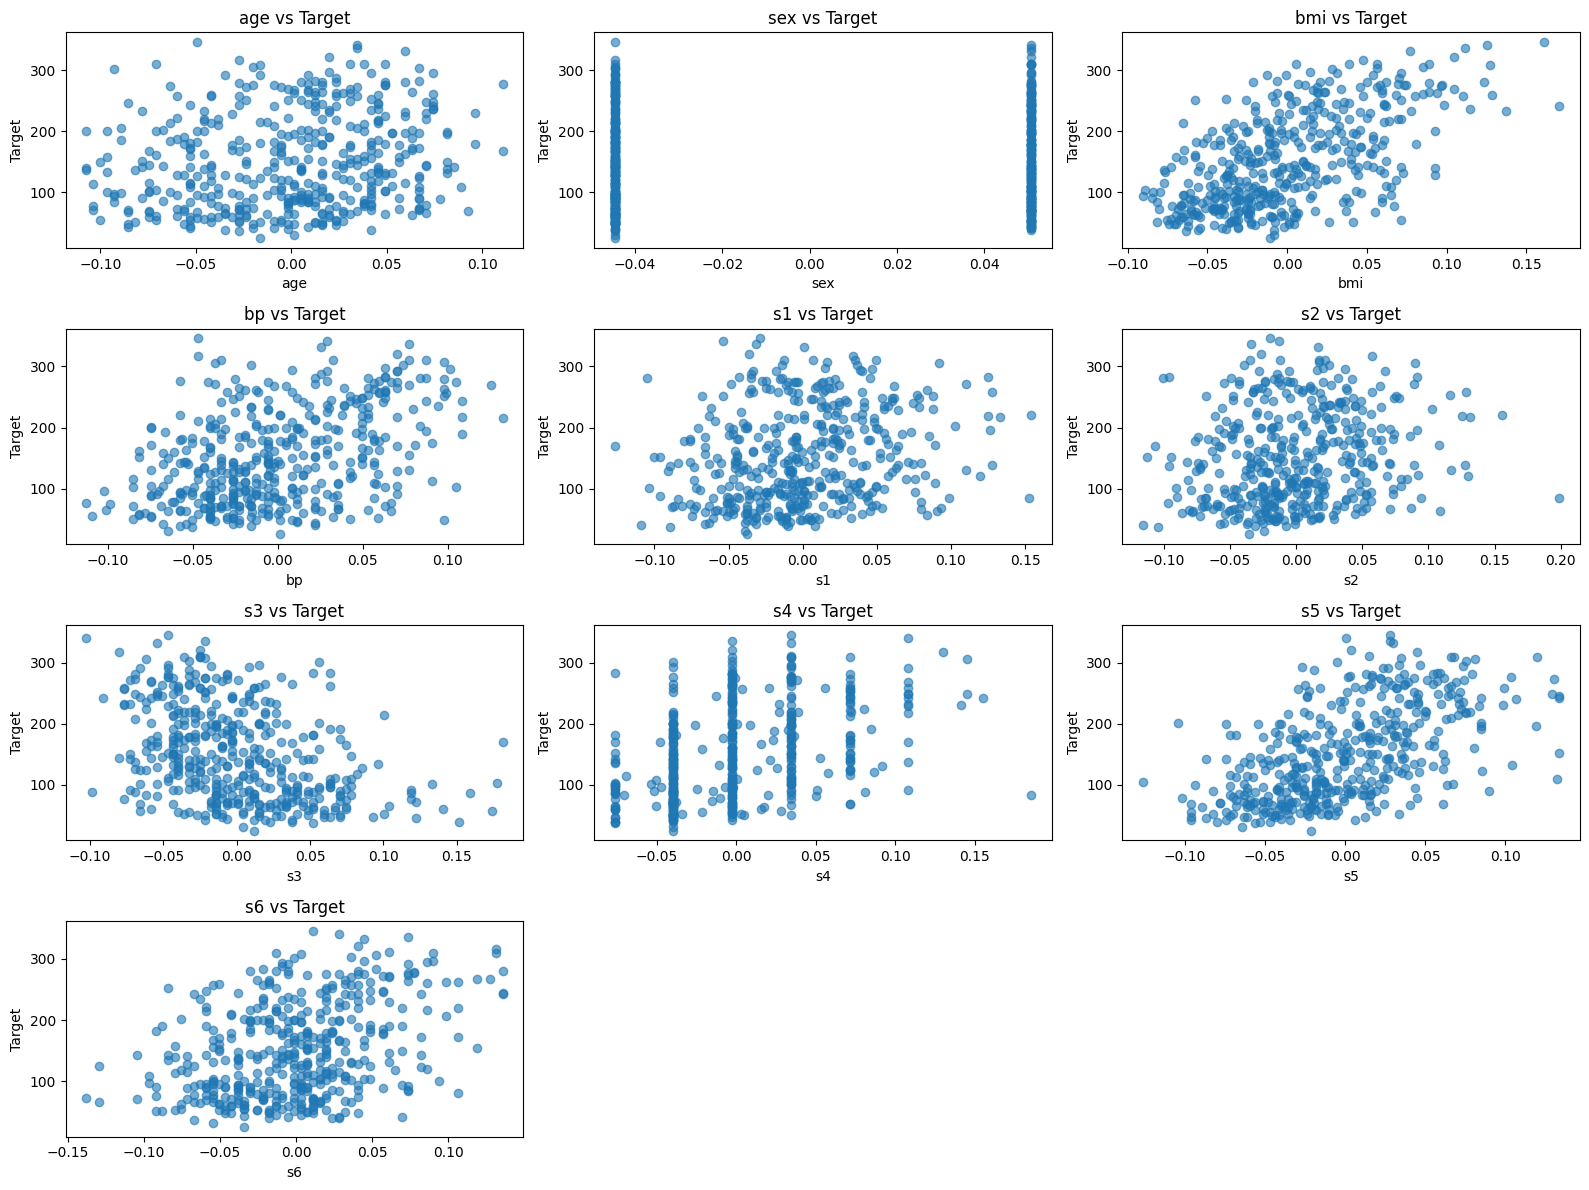

In [3]:

# STEP 3.1: SCATTER PLOTS

features = diabetes.feature_names

plt.figure(figsize=(16, 12))

for i, feature in enumerate(features):
    plt.subplot(4, 3, i + 1)
    plt.scatter(df[feature], df['Target'], alpha=0.6)
    plt.xlabel(feature)
    plt.ylabel('Target')
    plt.title(f'{feature} vs Target')

plt.tight_layout()
plt.show()



Correlation Matrix:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,Target
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133,0.043062
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483


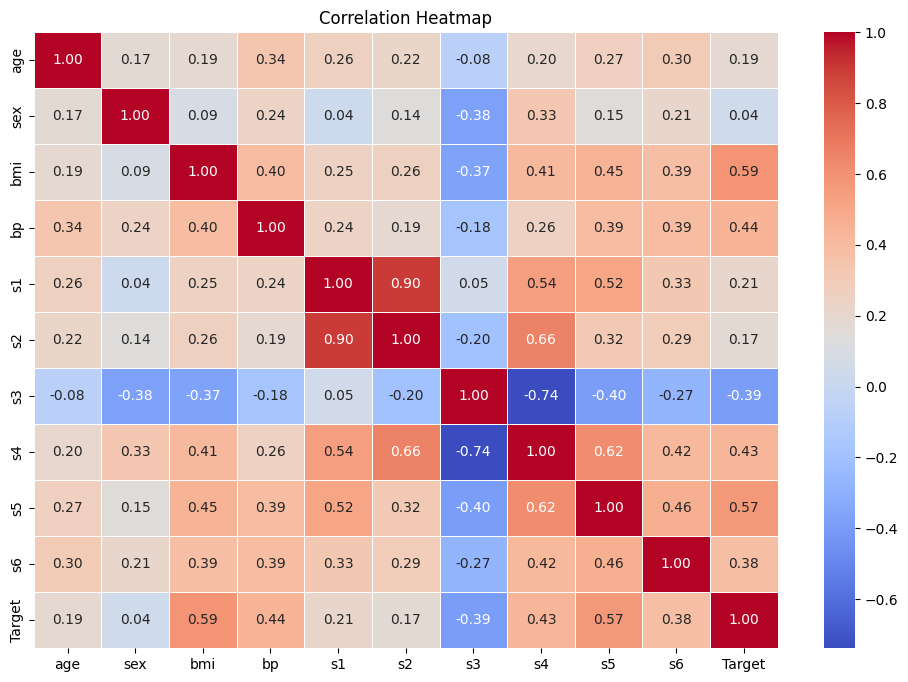


Correlation with Target:
Target    1.000000
bmi       0.586450
s5        0.565883
bp        0.441482
s4        0.430453
s6        0.382483
s1        0.212022
age       0.187889
s2        0.174054
sex       0.043062
s3       -0.394789
Name: Target, dtype: float64


In [4]:

# STEP 3.2: CORRELATION MATRIX

correlation = df.corr()

print("Correlation Matrix:")
display(correlation)

# Plot heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

# Correlation with target
print("\nCorrelation with Target:")
print(correlation['Target'].sort_values(ascending=False))



Observations:

1. Scatter plots show the relationship between
   different input features and the target variable.

2. The correlation matrix measures the strength
   and direction of relationships between variables.

3. Positive correlation means both variables tend
   to increase together, while negative correlation
   means one tends to decrease as the other increases.

4. Correlation between input features helps identify
   possible multicollinearity.

5. Correlation does not prove causation.

In [5]:

# STEP 4: MANUAL MULTIPLE LINEAR REGRESSION

# Select 6 observations and 2 features
sample = df[['bmi', 's5', 'Target']].head(6)

print("Selected 6 Observations:")
display(sample)

# Create X1, X2 and Y
X = np.column_stack((
    np.ones(len(sample)),
    sample['bmi'],
    sample['s5']
))

y = sample['Target'].values

print("\nDesign Matrix X:")
print(X)

print("\nTarget Vector Y:")
print(y)

# Calculate X transpose X
X_transpose = X.T

XTX = X_transpose @ X

print("\nX Transpose X:")
print(XTX)

# Calculate X transpose Y
XTY = X_transpose @ y

print("\nX Transpose Y:")
print(XTY)

# Solve normal equations
coefficients = np.linalg.solve(XTX, XTY)

b0, b1, b2 = coefficients

print("\nRegression Coefficients:")
print("b0 (Intercept):", b0)
print("b1 (bmi):", b1)
print("b2 (s5):", b2)

# Regression equation
print("\nRegression Equation:")
print(f"Y = {b0:.4f} + ({b1:.4f} * bmi) + ({b2:.4f} * s5)")

# Predict first observation
prediction = X[0] @ coefficients

actual = y[0]

residual = actual - prediction

print("\nPrediction for First Observation:")
print("Actual Value:", actual)
print("Predicted Value:", prediction)
print("Residual:", residual)


Selected 6 Observations:


,bmi,s5,Target
0,0.061696,0.019907,151.0
1,-0.051474,-0.068332,75.0
2,0.044451,0.002861,141.0
3,-0.011595,0.022688,206.0
4,-0.036385,-0.031988,135.0
5,-0.040696,-0.041176,97.0



Design Matrix X:
[[ 1.          0.06169621  0.01990749]
 [ 1.         -0.05147406 -0.06833155]
 [ 1.          0.04445121  0.00286131]
 [ 1.         -0.01159501  0.02268774]
 [ 1.         -0.03638469 -0.03198764]
 [ 1.         -0.04069594 -0.04117617]]

Target Vector Y:
[151.  75. 141. 206. 135.  97.]

X Transpose X:
[[ 6.         -0.03400229 -0.09603881]
 [-0.03400229  0.01154636  0.00744921]
 [-0.09603881  0.00744921  0.00830711]]

X Transpose Y:
[ 8.05000000e+02  4.75181008e-01 -5.35413507e+00]

Regression Coefficients:
b0 (Intercept): 158.5106152149008
b1 (bmi): -613.3644683725454
b2 (s5): 1738.041960462294

Regression Equation:
Y = 158.5106 + (-613.3645 * bmi) + (1738.0420 * s5)

Prediction for First Observation:
Actual Value: 151.0
Predicted Value: 155.2684005945529
Residual: -4.268400594552901


In [11]:

# STEP 5.1: VERIFY MANUAL CALCULATIONS

# Use the same 6 observations and 2 features
X_sample = sample[['bmi', 's5']]
y_sample = sample['Target']

# Train library model
manual_model = LinearRegression()
manual_model.fit(X_sample, y_sample)

print("Manual Calculation vs Scikit-learn")

print("\nManual Intercept:", b0)
print("Library Intercept:", manual_model.intercept_)

print("\nManual Coefficients:", [b1, b2])
print("Library Coefficients:", manual_model.coef_)

print("\nVerification:")
print("Both methods should give approximately the same values.")


Manual Calculation vs Scikit-learn

Manual Intercept: 158.5106152149008
Library Intercept: 158.5106152149008

Manual Coefficients: [np.float64(-613.3644683725454), np.float64(1738.041960462294)]
Library Coefficients: [-613.36446837 1738.04196046]

Verification:
Both methods should give approximately the same values.


In [10]:

# STEP 5.2: TRAIN TEST SPLIT

# Define input and target
X = df.drop('Target', axis=1)
y = df['Target']

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (353, 10)
Testing Data: (89, 10)


In [9]:

# STEP 5.3: TRAIN REGRESSION MODELS

# Simple Linear Regression using BMI
simple_model = LinearRegression()
simple_model.fit(X_train[['bmi']], y_train)

# Multiple Linear Regression using all features
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Predictions
simple_predictions = simple_model.predict(X_test[['bmi']])
multiple_predictions = multiple_model.predict(X_test)

# Display model coefficients
print("SIMPLE LINEAR REGRESSION")
print("Intercept:", simple_model.intercept_)
print("BMI Coefficient:", simple_model.coef_[0])

print("\nMULTIPLE LINEAR REGRESSION")
print("Intercept:", multiple_model.intercept_)

print("\nFeature Coefficients:")
for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(feature, ":", coefficient)


SIMPLE LINEAR REGRESSION
Intercept: 152.00335421448167
BMI Coefficient: 998.5776891375598

MULTIPLE LINEAR REGRESSION
Intercept: 151.34560453985995

Feature Coefficients:
age : 37.904021350074984
sex : -241.96436231273995
bmi : 542.4287585162899
bp : 347.70384391385636
s1 : -931.4888458835163
s2 : 518.0622769833376
s3 : 163.41998299131035
s4 : 275.3179015786484
s5 : 736.1988589046839
s6 : 48.67065743196543


In [12]:

# STEP 6.1: MODEL EVALUATION

def evaluate_model(y_actual, y_predicted, features_count):
    n = len(y_actual)

    mae = mean_absolute_error(y_actual, y_predicted)
    mse = mean_squared_error(y_actual, y_predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_actual, y_predicted)

    adjusted_r2 = 1 - (
        (1 - r2) * (n - 1) / (n - features_count - 1)
    )

    return [mae, mse, rmse, r2, adjusted_r2]


# Evaluate simple model
simple_metrics = evaluate_model(
    y_test, simple_predictions, 1
)

# Evaluate multiple model
multiple_metrics = evaluate_model(
    y_test, multiple_predictions, X_test.shape[1]
)

# Comparison table
results = pd.DataFrame(
    [simple_metrics, multiple_metrics],
    columns=['MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2'],
    index=['Simple Linear Regression', 'Multiple Linear Regression']
)

print("MODEL PERFORMANCE COMPARISON")
display(results)


MODEL PERFORMANCE COMPARISON


,MAE,MSE,RMSE,R2,Adjusted R2
Simple Linear Regression,52.259976,4061.825928,63.732456,0.233350,0.224538
Multiple Linear Regression,42.794095,2900.193628,53.853446,0.452603,0.382424


Model Comparison:

Simple Linear Regression uses only BMI as an input feature,
whereas Multiple Linear Regression uses all ten features.

The performance of both models is compared using MAE, MSE,
RMSE, R2 and Adjusted R2 on the test dataset.

The model with lower prediction errors and better R2 values
is considered preferable.

Additional features are useful only if they improve
performance enough to justify the extra complexity.

In [13]:

# STEP 7: REGRESSION EQUATION

print("MULTIPLE LINEAR REGRESSION EQUATION")

equation = f"Target = {multiple_model.intercept_:.4f}"

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    equation += f" + ({coefficient:.4f} * {feature})"

print(equation)

print("\nCOEFFICIENT INTERPRETATION")

for feature, coefficient in zip(X.columns, multiple_model.coef_):
    print(
        f"A one-unit increase in {feature} changes "
        f"the predicted target by {coefficient:.4f}, "
        "holding other features constant."
    )


MULTIPLE LINEAR REGRESSION EQUATION
Target = 151.3456 + (37.9040 * age) + (-241.9644 * sex) + (542.4288 * bmi) + (347.7038 * bp) + (-931.4888 * s1) + (518.0623 * s2) + (163.4200 * s3) + (275.3179 * s4) + (736.1989 * s5) + (48.6707 * s6)

COEFFICIENT INTERPRETATION
A one-unit increase in age changes the predicted target by 37.9040, holding other features constant.
A one-unit increase in sex changes the predicted target by -241.9644, holding other features constant.
A one-unit increase in bmi changes the predicted target by 542.4288, holding other features constant.
A one-unit increase in bp changes the predicted target by 347.7038, holding other features constant.
A one-unit increase in s1 changes the predicted target by -931.4888, holding other features constant.
A one-unit increase in s2 changes the predicted target by 518.0623, holding other features constant.
A one-unit increase in s3 changes the predicted target by 163.4200, holding other features constant.
A one-unit increase in s

In [14]:
comparison = pd.DataFrame({
    'Actual Value': y_test.values,
    'Predicted Value': multiple_predictions
})

comparison['Difference'] = (
    comparison['Actual Value'] - comparison['Predicted Value']
)

print("ACTUAL VS PREDICTED VALUES")
display(comparison.head(15))

ACTUAL VS PREDICTED VALUES


,Actual Value,Predicted Value,Difference
0,219.0,139.547558,79.452442
1,70.0,179.517208,-109.517208
2,202.0,134.038756,67.961244
3,230.0,291.417029,-61.417029
4,111.0,123.789659,-12.789659
5,84.0,92.172347,-8.172347
6,242.0,258.232389,-16.232389
7,272.0,181.337321,90.662679
8,94.0,90.224113,3.775887
9,96.0,108.633759,-12.633759


In [16]:
residuals = y_test.values - multiple_predictions

print("Residual Analysis")
print("Mean Residual:", np.mean(residuals))
print("Minimum Residual:", np.min(residuals))
print("Maximum Residual:", np.max(residuals))

Residual Analysis
Mean Residual: 3.912840375077808
Minimum Residual: -154.49337473788216
Maximum Residual: 128.3332741927178


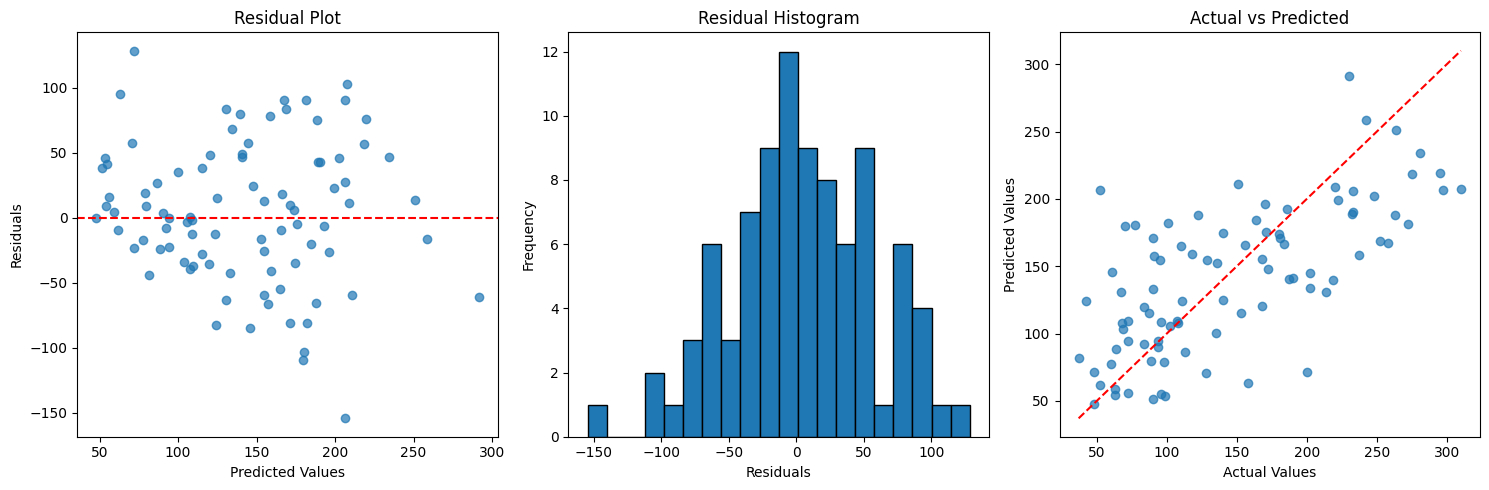

In [17]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(multiple_predictions, residuals, alpha=0.7)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.subplot(1, 3, 2)
plt.hist(residuals, bins=20, edgecolor='black')
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Residual Histogram")

plt.subplot(1, 3, 3)
plt.scatter(y_test, multiple_predictions, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")

plt.tight_layout()
plt.show()


In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_vif = sm.add_constant(X)

vif_data = pd.DataFrame()
vif_data['Feature'] = X_vif.columns
vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print("VARIANCE INFLATION FACTOR (VIF)")
display(vif_data)

VARIANCE INFLATION FACTOR (VIF)


,Feature,VIF
0,const,1.000000
1,age,1.217307
2,sex,1.278071
3,bmi,1.509437
4,bp,1.459428
5,s1,59.202510
6,s2,39.193370
7,s3,15.402156
8,s4,8.890986
9,s5,10.075967


### Regression Assumptions

Multiple Linear Regression is based on the following assumptions:

1. **Linearity:** There should be a linear relationship between input features and the target variable.

2. **Independence:** Observations and their errors should be independent of each other.

3. **Homoscedasticity:** Residuals should have approximately constant variance across predicted values.

4. **Normality of Residuals:** Residuals should be approximately normally distributed, especially for statistical inference.

5. **No Severe Multicollinearity:** Independent variables should not have very high correlations with each other. VIF is used to check multicollinearity.

**Conclusion:** Scatter plots, residual plots, residual histogram, correlation matrix and VIF analysis help evaluate these assumptions. Some assumptions may not be perfectly satisfied, so the model results should be interpreted carefully.

In [19]:
new_data = pd.DataFrame([{
    'age': 0.05,
    'sex': 0.05,
    'bmi': 0.04,
    'bp': 0.02,
    's1': -0.03,
    's2': -0.02,
    's3': -0.01,
    's4': 0.02,
    's5': 0.03,
    's6': 0.01
}])

new_prediction = multiple_model.predict(new_data)

print("NEW PATIENT DATA:")
display(new_data)

print("Predicted Diabetes Progression:", round(new_prediction[0], 2))

NEW PATIENT DATA:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.05,0.05,0.04,0.02,-0.03,-0.02,-0.01,0.02,0.03,0.01


Predicted Diabetes Progression: 213.82


### New Prediction

A new input record was created using the same features as the training dataset. The trained Multiple Linear Regression model was used to predict the target value.

This demonstrates how the model can make predictions for previously unseen data.

## Decision Log

| No. | Decision | Reason |
|---|---|---|
| 1 | Selected the Diabetes dataset from Scikit-learn | It contains numerical features and a continuous target variable. |
| 2 | Used all 10 numerical features | To study the combined effect of multiple features on the target. |
| 3 | Checked missing and duplicate values | To understand data quality before model training. |
| 4 | Used BMI for Simple Linear Regression | To compare a single-feature model with a multiple-feature model. |
| 5 | Used BMI and S5 for manual calculation | To demonstrate the least-squares method using two features. |
| 6 | Applied an 80:20 train-test split | To evaluate the model on unseen data. |
| 7 | Used Multiple Linear Regression | To predict the continuous target using multiple input features. |
| 8 | Evaluated using MAE, MSE, RMSE, R² and Adjusted R² | To measure and compare model performance. |
| 9 | Performed residual and VIF analysis | To examine regression assumptions and multicollinearity. |
| 10 | Tested a new input record | To demonstrate prediction on unseen data. |

### Final Conclusion

Multiple Linear Regression was implemented successfully using the Scikit-learn Diabetes dataset. Manual least-squares calculations were verified against the library implementation. Simple and multiple regression models were compared using evaluation metrics. Residual analysis and VIF were used to examine model assumptions and multicollinearity. Finally, the trained model was used to predict a new target value.